In [ ]:
# Install required packages (run once)
!pip -q install tensorflow-datasets scikit-learn seaborn

In [ ]:
import os, time, json, random, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 5       # For a quick test use 1; for final results use more epochs if time/GPU allows.
NUM_CLASSES = 5
AUTOTUNE = tf.data.AUTOTUNE
RESULT_DIR = "results"
os.makedirs(RESULT_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
(ds_all, ds_info) = tfds.load(
    "tf_flowers",
    split="train",
    as_supervised=True,
    with_info=True,
    shuffle_files=False
)
class_names = ds_info.features["label"].names
print("Classes:", class_names)
print("Total images:", ds_info.splits["train"].num_examples)

# Collect file-independent image/label arrays for a reproducible stratified split.
images, labels = [], []
for image, label in tfds.as_numpy(ds_all):
    images.append(image)
    labels.append(int(label))
images = np.array(images, dtype=object)
labels = np.array(labels, dtype=np.int32)

all_idx = np.arange(len(labels))
train_idx, temp_idx = train_test_split(
    all_idx, test_size=0.30, random_state=SEED, stratify=labels
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED, stratify=labels[temp_idx]
)

print(f"Train: {len(train_idx)} ({len(train_idx)/len(labels):.1%})")
print(f"Validation: {len(val_idx)} ({len(val_idx)/len(labels):.1%})")
print(f"Test: {len(test_idx)} ({len(test_idx)/len(labels):.1%})")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.HBRPOI_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Total images: 3670
Train: 2569 (70.0%)
Validation: 550 (15.0%)
Test: 551 (15.0%)


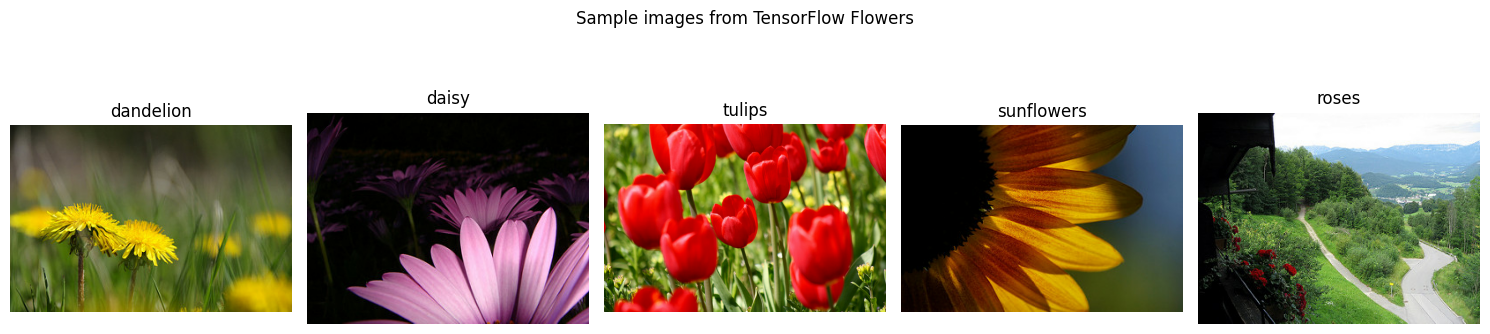

In [ ]:
# Plot sample images from all five classes
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(15, 4))
for class_id, ax in enumerate(axes):
    sample_id = np.where(labels == class_id)[0][0]
    ax.imshow(images[sample_id])
    ax.set_title(class_names[class_id])
    ax.axis("off")
plt.suptitle("Sample images from TensorFlow Flowers")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/01_sample_images.png", dpi=160, bbox_inches="tight")
plt.show()

In [ ]:
def preprocess_image(image, label, training=False):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    if training:
        image = tf.image.random_flip_left_right(image)
        image = tf.image.random_brightness(image, max_delta=0.08)
        image = tf.image.random_contrast(image, lower=0.9, upper=1.1)
    image = tf.keras.applications.resnet50.preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES)
    return image, label

def make_dataset(indices, training=False):
    # Convert object array to a list so TensorFlow can build a dataset from variable-sized images.
    subset_images = [images[i] for i in indices]
    subset_labels = labels[indices]
    ds = tf.data.Dataset.from_generator(
        lambda: iter(zip(subset_images, subset_labels)),
        output_signature=(
            tf.TensorSpec(shape=(None, None, 3), dtype=tf.uint8),
            tf.TensorSpec(shape=(), dtype=tf.int32)
        )
    )
    if training:
        ds = ds.shuffle(len(indices), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda x, y: preprocess_image(x, y, training), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_idx, training=True)
val_ds = make_dataset(val_idx)
test_ds = make_dataset(test_idx)

In [ ]:
from tensorflow.keras import layers, Model

@tf.keras.utils.register_keras_serializable()
class ChannelAttention(layers.Layer):
    def __init__(self, ratio=16, **kwargs):
        super().__init__(**kwargs)
        self.ratio = ratio
    def build(self, input_shape):
        channels = int(input_shape[-1])
        hidden = max(channels // self.ratio, 1)
        self.pool = layers.GlobalAveragePooling2D(keepdims=True)
        self.fc1 = layers.Conv2D(hidden, 1, activation="relu")
        self.fc2 = layers.Conv2D(channels, 1, activation="sigmoid")
        super().build(input_shape)
    def call(self, x):
        weights = self.fc2(self.fc1(self.pool(x)))
        return x * weights
    def get_config(self):
        return {**super().get_config(), "ratio": self.ratio}

@tf.keras.utils.register_keras_serializable()
class SpatialAttention(layers.Layer):
    def __init__(self, kernel_size=7, **kwargs):
        super().__init__(**kwargs)
        self.kernel_size = kernel_size
        self.conv = layers.Conv2D(1, kernel_size, padding="same", activation="sigmoid", use_bias=False)
    def call(self, x):
        avg_map = tf.reduce_mean(x, axis=-1, keepdims=True)
        max_map = tf.reduce_max(x, axis=-1, keepdims=True)
        weights = self.conv(tf.concat([avg_map, max_map], axis=-1))
        return x * weights
    def get_config(self):
        return {**super().get_config(), "kernel_size": self.kernel_size}

@tf.keras.utils.register_keras_serializable()
class LiteSelfAttention(layers.Layer):
    def __init__(self, key_dim=64, **kwargs):
        super().__init__(**kwargs)
        self.key_dim = key_dim
    def build(self, input_shape):
        channels = int(input_shape[-1])
        d = min(self.key_dim, channels)
        self.q = layers.Conv2D(d, 1, use_bias=False)
        self.k = layers.Conv2D(d, 1, use_bias=False)
        self.v = layers.Conv2D(channels, 1, use_bias=False)
        self.gamma = self.add_weight(name="gamma", shape=(), initializer="zeros", trainable=True)
        super().build(input_shape)
    def call(self, x):
        shape = tf.shape(x)
        b, h, w = shape[0], shape[1], shape[2]
        q = tf.reshape(self.q(x), [b, h*w, -1])
        k = tf.reshape(self.k(x), [b, h*w, -1])
        v = tf.reshape(self.v(x), [b, h*w, -1])
        scores = tf.matmul(q, k, transpose_b=True) / tf.sqrt(tf.cast(tf.shape(k)[-1], tf.float32))
        weights = tf.nn.softmax(scores, axis=-1)
        attended = tf.matmul(weights, v)
        attended = tf.reshape(attended, [b, h, w, tf.shape(v)[-1]])
        return x + self.gamma * attended
    def get_config(self):
        return {**super().get_config(), "key_dim": self.key_dim}

def apply_attention(x, attention="none", order="channel_spatial", kernel_size=7):
    if attention in ("channel", "channel_spatial", "cbam"):
        x = ChannelAttention(name="channel_attention")(x)
    if attention in ("spatial", "channel_spatial", "cbam"):
        x = SpatialAttention(kernel_size=kernel_size, name="spatial_attention")(x)
    if attention == "spatial_channel":
        x = SpatialAttention(kernel_size=kernel_size, name="spatial_attention")(x)
        x = ChannelAttention(name="channel_attention")(x)
    if attention == "self":
        x = LiteSelfAttention(name="self_attention")(x)
    return x

## Task 3 — Build and train models
ResNet50 stage outputs used here:
- P2: `conv3_block4_out` (28 × 28 × 512)
- P3: `conv4_block6_out` (14 × 14 × 1024)
- P4: `conv5_block3_out` (7 × 7 × 2048)

The baseline uses the final ResNet50 output. For a manageable first run, this notebook freezes the pretrained feature extractor and trains the new classification/attention layers. The same split, batch size, and epoch count are used for all models.

In [ ]:
def build_model(attention="none", position="P4", kernel_size=7, order="channel_spatial",
                extra_mechanism=None, train_backbone=False):
    base = tf.keras.applications.ResNet50(
        include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    stage_layer = {
        "P2": "conv3_block4_out",
        "P3": "conv4_block6_out",
        "P4": "conv5_block3_out",
        "BASELINE": "conv5_block3_out"
    }[position]
    feature_model = Model(base.input, base.get_layer(stage_layer).output, name=f"resnet50_{position}")
    feature_model.trainable = train_backbone
    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    x = feature_model(inputs, training=False)
    if attention != "none":
        if attention == "order":
            x = apply_attention(x, "spatial_channel" if order == "spatial_channel" else "channel_spatial", kernel_size)
        elif attention == "extra_se":
            # Squeeze-and-Excitation: global average pooling and channel reweighting
            channels = int(x.shape[-1])
            z = layers.GlobalAveragePooling2D(keepdims=True)(x)
            z = layers.Conv2D(max(channels // 16, 1), 1, activation="relu")(z)
            z = layers.Conv2D(channels, 1, activation="sigmoid")(z)
            x = layers.Multiply()([x, z])
        elif attention == "extra_eca":
            # Efficient Channel Attention: lightweight 1-D convolution across channel descriptor
            channels = int(x.shape[-1])
            z = layers.GlobalAveragePooling2D()(x)
            z = layers.Reshape((channels, 1))(z)
            z = layers.Conv1D(1, 3, padding="same", use_bias=False)(z)
            z = layers.Activation("sigmoid")(z)
            z = layers.Reshape((1, 1, channels))(z)
            x = layers.Multiply()([x, z])
        else:
            x = apply_attention(x, attention, order, kernel_size)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dropout(0.3, name="dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="flower_predictions")(x)
    model = Model(inputs, outputs, name=f"{position}_{attention}")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

def train_one(name, attention="none", position="P4", kernel_size=7, order="channel_spatial"):
    print("\nTraining:", name)
    model = build_model(attention=attention, position=position, kernel_size=kernel_size, order=order)
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=1, min_lr=1e-6)
    ]
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=1)
    return model, history

# Mandatory models. Change EPOCHS near the top for longer training.
experiment_specs = [
    ("Baseline", "none", "P4"),
    ("Channel_P3", "channel", "P3"),
    ("Spatial_P3", "spatial", "P3"),
    ("ChannelSpatial_P3", "channel_spatial", "P3"),
    ("ChannelSpatial_P2", "channel_spatial", "P2"),
    ("ChannelSpatial_P4", "channel_spatial", "P4"),
    ("SelfAttention_P3", "self", "P3"),
]
models, histories = {}, {}
for name, attention, position in experiment_specs:
    models[name], histories[name] = train_one(name, attention, position)
    models[name].save(f"{RESULT_DIR}/{name}.keras")
    with open(f"{RESULT_DIR}/{name}_history.json", "w") as f:
        json.dump({k: [float(v) for v in vals] for k, vals in histories[name].history.items()}, f)


Training: Baseline
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5
    161/Unknown 29s 88ms/step - accuracy: 0.6192 - loss: 1.0577

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 41s 162ms/step - accuracy: 0.7404 - loss: 0.7096 - val_accuracy: 0.9000 - val_loss: 0.3166 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 11s 66ms/step - accuracy: 0.8879 - loss: 0.3290 - val_accuracy: 0.9218 - val_loss: 0.2585 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 64ms/step - accuracy: 0.9093 - loss: 0.2504 - val_accuracy: 0.8891 - val_loss: 0.2917 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 121ms/step - accuracy: 0.9408 - loss: 0.1855 - val_accuracy: 0.9291 - val_loss: 0.2387 - learning_rate: 3.0000e-04
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 12s 70ms/step - accuracy: 0.9443 - loss: 0.1757 - val_accuracy: 0.9273 - val_loss: 0.2297 - learning_rate: 3.0000e-04

Training: Channel_P3
Epoch 1/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 32s 128ms/step - accuracy: 0.6863 - loss: 0.8688 - val_accuracy: 0.8055 - val_loss: 0.5315 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 16s 92ms/step - accu

## Task 4 — Training/validation accuracy and loss curves
These plots use each model's recorded training history.

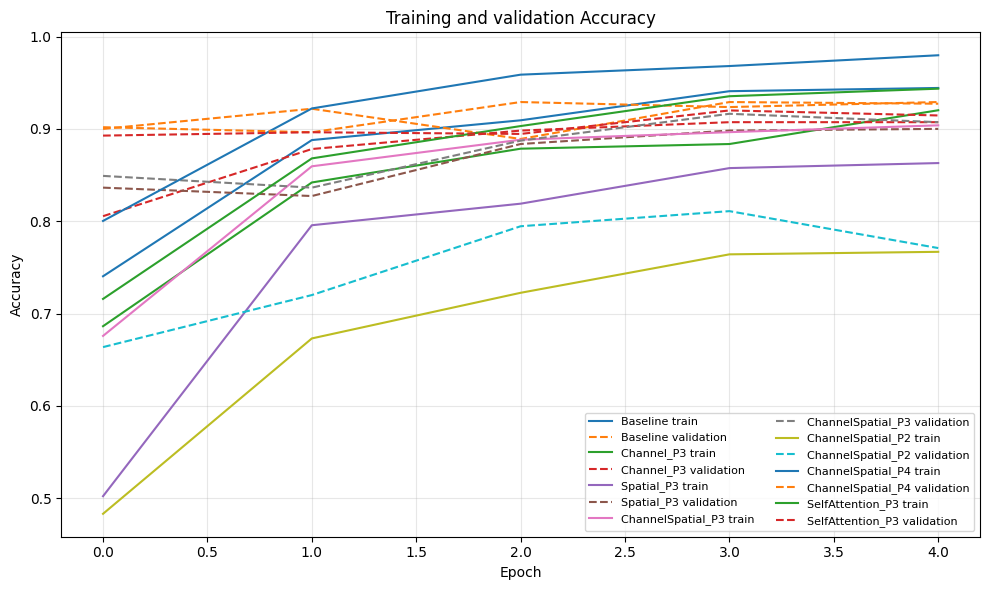

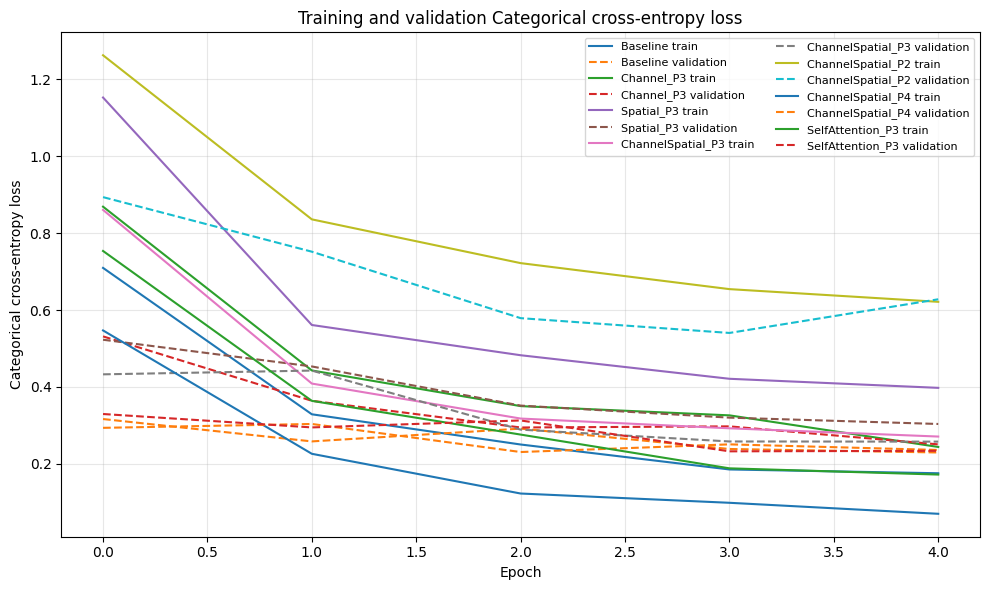

In [ ]:
def plot_learning_curves(histories, metric, ylabel, filename):
    plt.figure(figsize=(10, 6))
    for name, hist in histories.items():
        if metric in hist.history:
            plt.plot(hist.history[metric], label=f"{name} train")
        val_metric = "val_" + metric
        if val_metric in hist.history:
            plt.plot(hist.history[val_metric], linestyle="--", label=f"{name} validation")
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(f"Training and validation {ylabel}")
    plt.legend(fontsize=8, ncol=2)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{RESULT_DIR}/{filename}", dpi=160, bbox_inches="tight")
    plt.show()

plot_learning_curves(histories, "accuracy", "Accuracy", "02_accuracy_curves.png")
plot_learning_curves(histories, "loss", "Categorical cross-entropy loss", "03_loss_curves.png")

## Task 5 — Test metrics, parameter counts, inference time, confusion matrices
The following cell calculates all required quantitative metrics on the held-out test set.

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Trainable Parameters,Total Parameters,Inference Time (s/image)
0,Baseline,0.9165,0.9146,0.9175,0.9156,10245,23597957,0.0170
1,Channel_P3,0.9129,0.9138,0.9149,0.9138,137285,8726469,0.0144
2,Spatial_P3,0.9111,0.9121,0.9125,0.9118,5223,8594407,0.0144
3,ChannelSpatial_P3,0.9093,0.9104,0.9103,0.9097,137383,8726567,0.0147
4,ChannelSpatial_P2,0.7877,0.7934,0.7876,0.7872,35975,1496071,0.0090
5,ChannelSpatial_P4,0.9274,0.9273,0.9277,0.9274,536807,24124519,0.0178
6,SelfAttention_P3,0.9056,0.9056,0.9060,0.9050,1184774,9773958,0.0148


Saved: results/results_metrics.csv


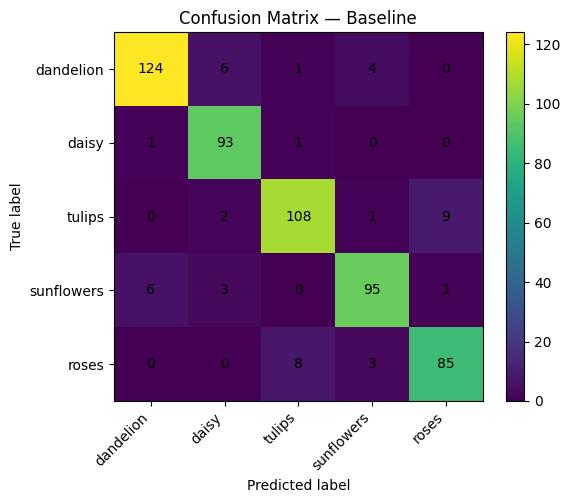

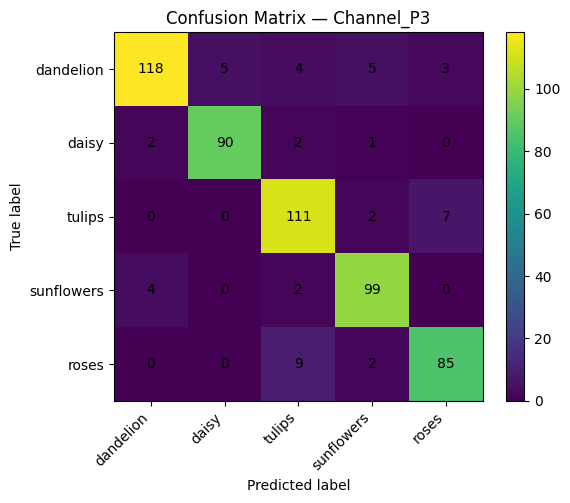

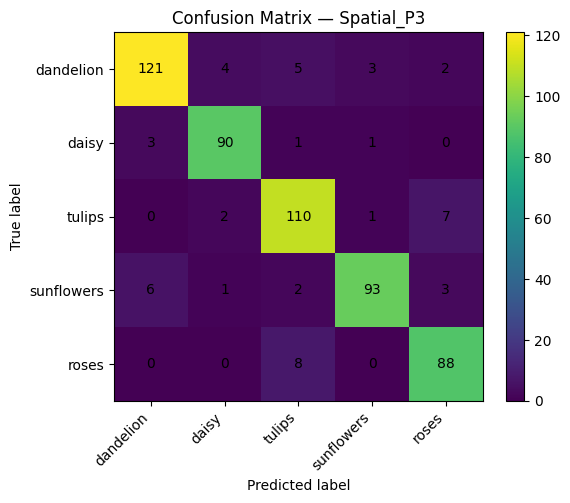

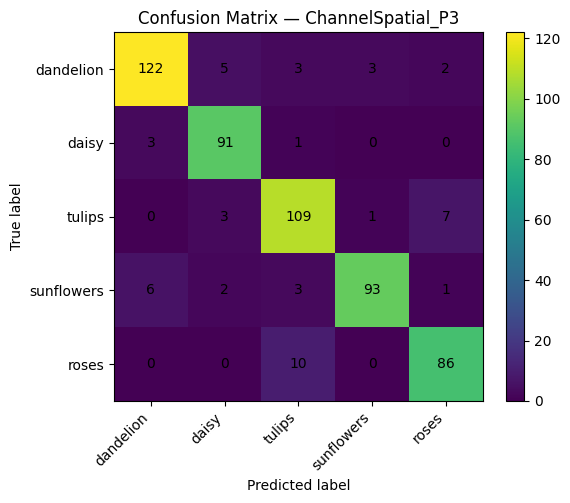

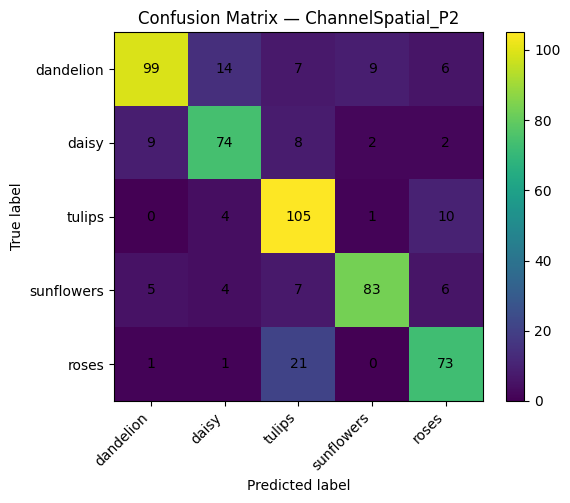

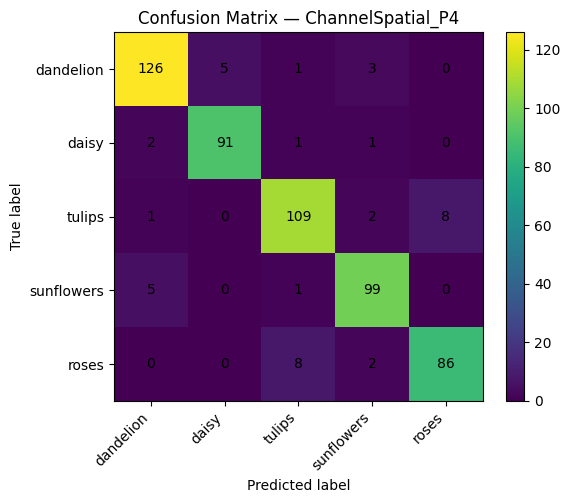

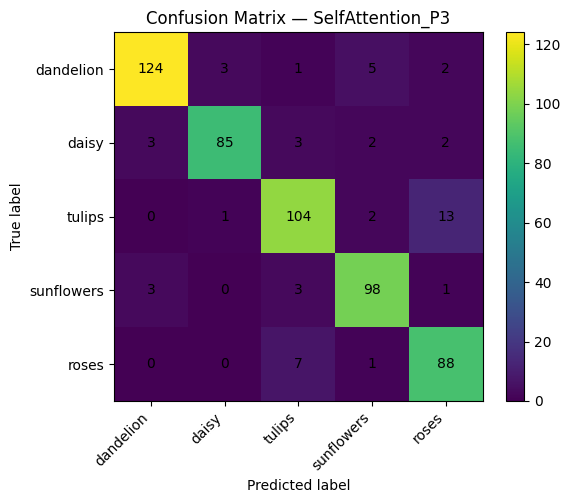


Classification report: Baseline
              precision    recall  f1-score   support

   dandelion       0.95      0.92      0.93       135
       daisy       0.89      0.98      0.93        95
      tulips       0.92      0.90      0.91       120
  sunflowers       0.92      0.90      0.91       105
       roses       0.89      0.89      0.89        96

    accuracy                           0.92       551
   macro avg       0.91      0.92      0.92       551
weighted avg       0.92      0.92      0.92       551


Classification report: ChannelSpatial_P3
              precision    recall  f1-score   support

   dandelion       0.93      0.90      0.92       135
       daisy       0.90      0.96      0.93        95
      tulips       0.87      0.91      0.89       120
  sunflowers       0.96      0.89      0.92       105
       roses       0.90      0.90      0.90        96

    accuracy                           0.91       551
   macro avg       0.91      0.91      0.91       551
we

In [ ]:
def time_inference(model, repeats=3):
    # Warm up model first
    for batch_x, _ in test_ds.take(1):
        _ = model(batch_x, training=False)
    total_images, total_seconds = 0, 0.0
    for _ in range(repeats):
        for batch_x, _ in test_ds:
            start = time.perf_counter()
            _ = model(batch_x, training=False)
            # Force completion for GPU timing
            _ = _.numpy()
            total_seconds += time.perf_counter() - start
            total_images += int(batch_x.shape[0])
    return total_seconds / max(total_images, 1)

def evaluate_model(model, name):
    y_true, y_prob = [], []
    for xb, yb in test_ds:
        probs = model.predict(xb, verbose=0)
        y_prob.extend(probs)
        y_true.extend(np.argmax(yb.numpy(), axis=1))
    y_true = np.array(y_true)
    y_pred = np.argmax(np.array(y_prob), axis=1)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Trainable Parameters": int(sum(np.prod(v.shape) for v in model.trainable_variables)),
        "Total Parameters": int(model.count_params()),
        "Inference Time (s/image)": time_inference(model),
        "y_true": y_true, "y_pred": y_pred
    }

results = []
predictions = {}
for name, model in models.items():
    r = evaluate_model(model, name)
    predictions[name] = (r.pop("y_true"), r.pop("y_pred"))
    results.append(r)

results_df = pd.DataFrame(results)
display(results_df.round(4))
results_df.to_csv(f"{RESULT_DIR}/results_metrics.csv", index=False)
print("Saved:", f"{RESULT_DIR}/results_metrics.csv")

for name in models:
    y_true, y_pred = predictions[name]
    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    plt.figure(figsize=(6, 5))
    plt.imshow(cm, interpolation="nearest")
    plt.title(f"Confusion Matrix — {name}")
    plt.colorbar()
    ticks = np.arange(NUM_CLASSES)
    plt.xticks(ticks, class_names, rotation=45, ha="right")
    plt.yticks(ticks, class_names)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            plt.text(j, i, cm[i, j], ha="center", va="center")
    plt.tight_layout()
    plt.savefig(f"{RESULT_DIR}/confusion_{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

# Detailed class-wise report for the baseline and selected attention model
for name in ["Baseline", "ChannelSpatial_P3"]:
    y_true, y_pred = predictions[name]
    print("\nClassification report:", name)
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

## Task 6 — Performance comparison graphs
Creates accuracy, macro-F1, parameters-vs-accuracy, and inference-time-vs-F1 plots.

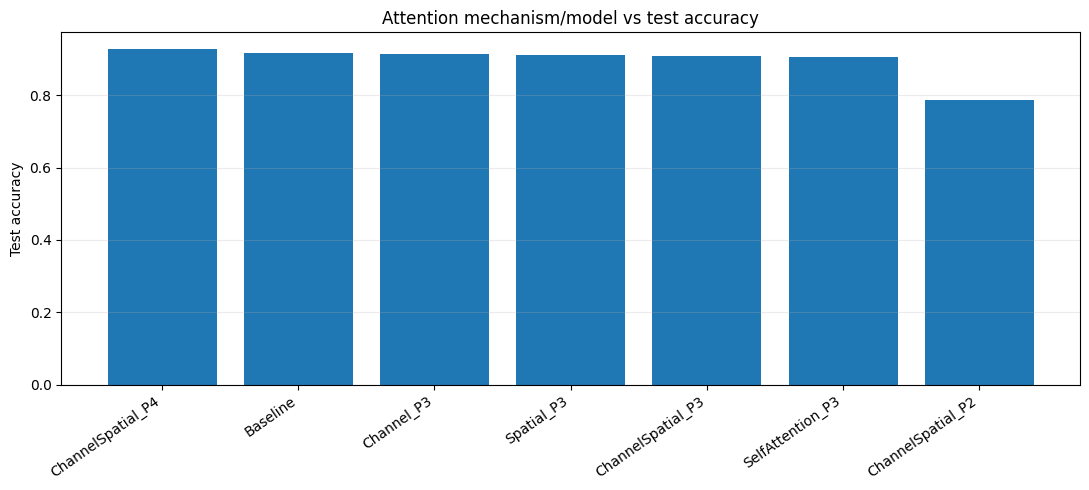

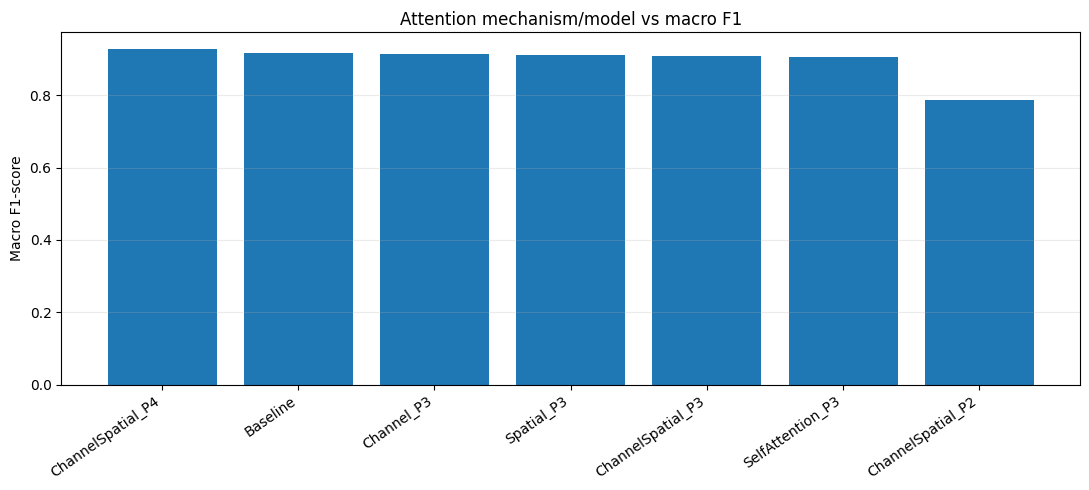

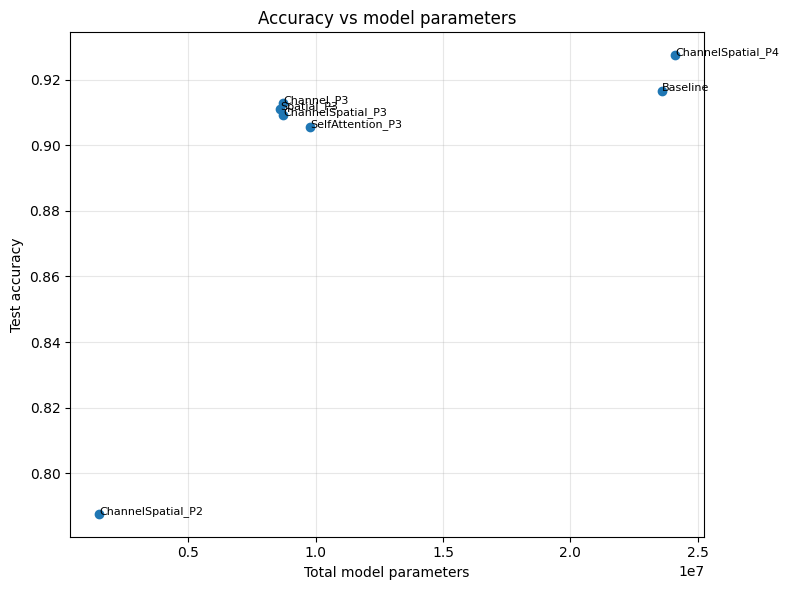

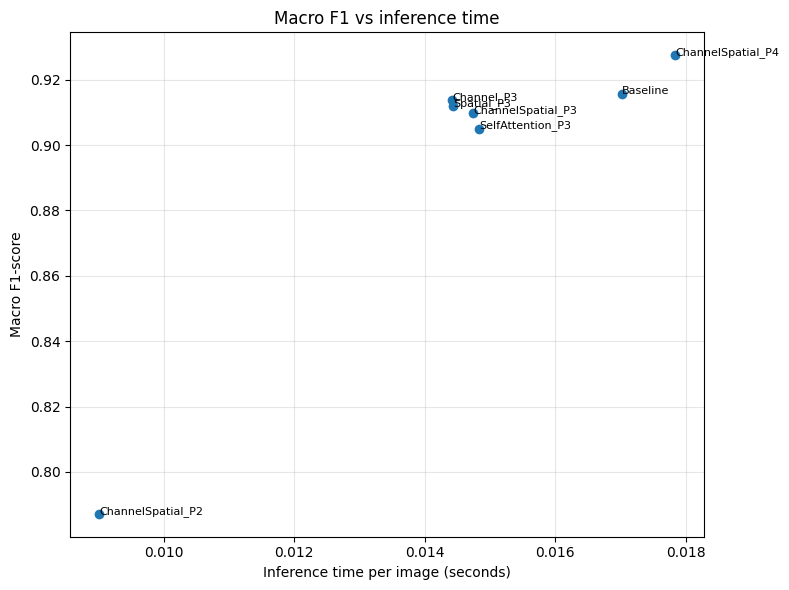

In [ ]:
def bar_plot(metric, title, ylabel, filename):
    data = results_df.sort_values(metric, ascending=False)
    plt.figure(figsize=(11, 5))
    plt.bar(data["Model"], data[metric])
    plt.xticks(rotation=35, ha="right")
    plt.title(title)
    plt.ylabel(ylabel)
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.savefig(f"{RESULT_DIR}/{filename}", dpi=160, bbox_inches="tight")
    plt.show()

bar_plot("Accuracy", "Attention mechanism/model vs test accuracy", "Test accuracy", "04_accuracy_comparison.png")
bar_plot("Macro F1", "Attention mechanism/model vs macro F1", "Macro F1-score", "05_macro_f1_comparison.png")

plt.figure(figsize=(8, 6))
plt.scatter(results_df["Total Parameters"], results_df["Accuracy"])
for _, row in results_df.iterrows():
    plt.annotate(row["Model"], (row["Total Parameters"], row["Accuracy"]), fontsize=8)
plt.xlabel("Total model parameters")
plt.ylabel("Test accuracy")
plt.title("Accuracy vs model parameters")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/06_accuracy_vs_parameters.png", dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(results_df["Inference Time (s/image)"], results_df["Macro F1"])
for _, row in results_df.iterrows():
    plt.annotate(row["Model"], (row["Inference Time (s/image)"], row["Macro F1"]), fontsize=8)
plt.xlabel("Inference time per image (seconds)")
plt.ylabel("Macro F1-score")
plt.title("Macro F1 vs inference time")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/07_f1_vs_inference_time.png", dpi=160, bbox_inches="tight")
plt.show()

## Task 7 — Attention maps, channel weights, feature maps, and overlays
These helpers extract internal maps from a trained model. Run the next cell after the models have trained.

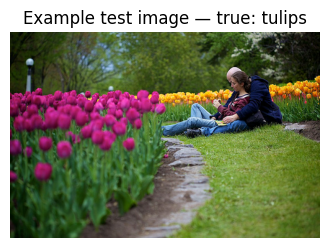

Baseline | true: tulips | predicted: tulips
ChannelSpatial_P3 | true: tulips | predicted: tulips


In [ ]:
def get_test_image(index=0):
    # The test split order follows test_idx. Return a raw image and true class label.
    raw = images[test_idx[index]]
    label = labels[test_idx[index]]
    resized = tf.image.resize(raw, (IMG_SIZE, IMG_SIZE)).numpy().astype(np.float32)
    model_input = tf.keras.applications.resnet50.preprocess_input(resized.copy())
    return raw, resized, label, np.expand_dims(model_input, axis=0)

def show_overlay(image, heatmap, title, filename):
    heatmap = np.squeeze(heatmap)
    heatmap = tf.image.resize(heatmap[..., None], (IMG_SIZE, IMG_SIZE)).numpy().squeeze()
    heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
    plt.figure(figsize=(5, 5))
    plt.imshow(image.astype("uint8"))
    plt.imshow(heatmap, alpha=0.45, cmap="jet")
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(f"{RESULT_DIR}/{filename}", dpi=160, bbox_inches="tight")
    plt.show()

def get_attention_layer_model(model, layer_name, input_tensor):
    layer = model.get_layer(layer_name)
    return Model(model.inputs, layer.output)(input_tensor, training=False)

# Show one representative test image and predicted classes
raw_img, resized_img, true_label, x_img = get_test_image(0)
plt.figure(figsize=(4, 4))
plt.imshow(raw_img)
plt.title(f"Example test image — true: {class_names[true_label]}")
plt.axis("off")
plt.show()

for name in ["Baseline", "ChannelSpatial_P3"]:
    pred = int(np.argmax(models[name].predict(x_img, verbose=0)[0]))
    print(name, "| true:", class_names[true_label], "| predicted:", class_names[pred])

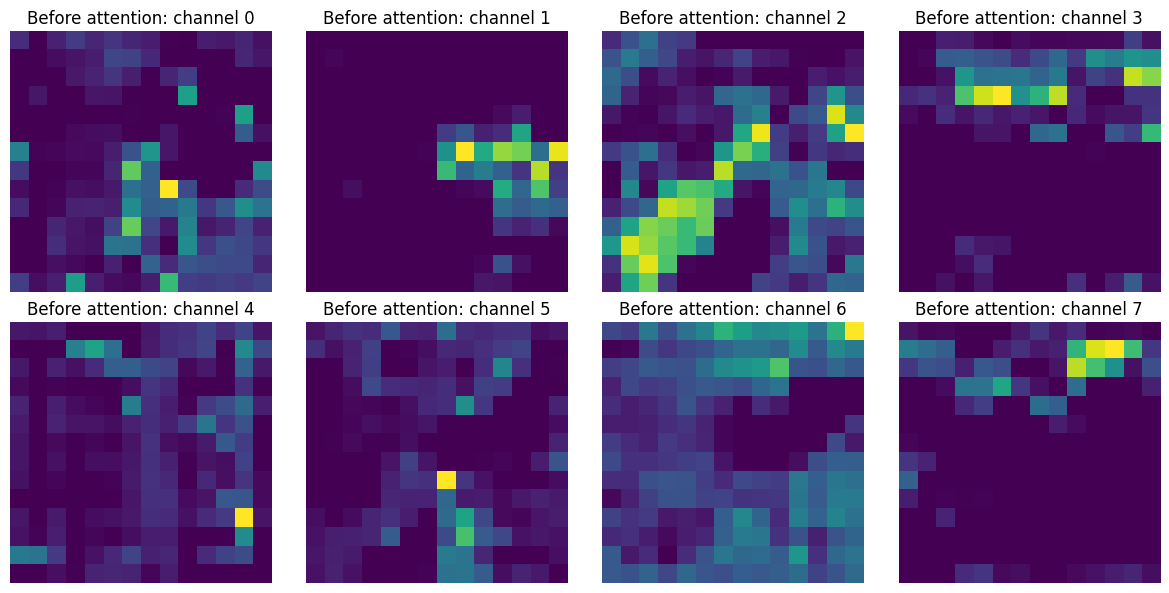

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['image']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


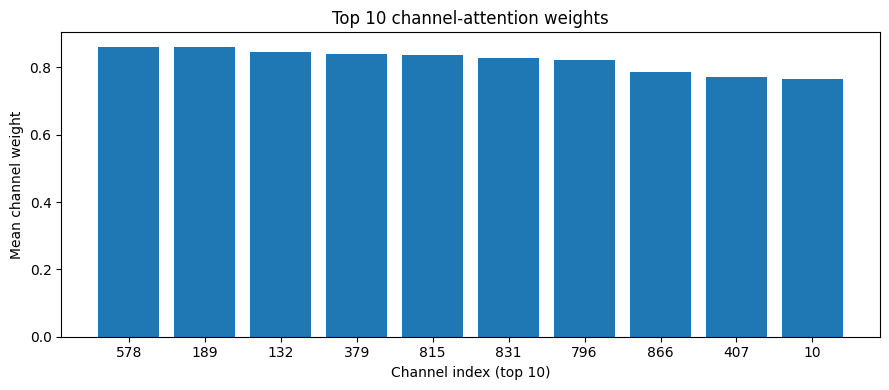

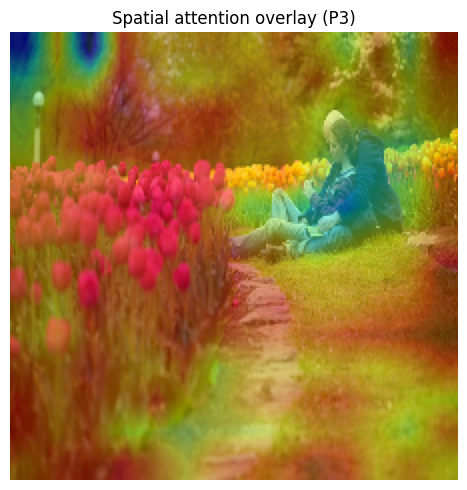

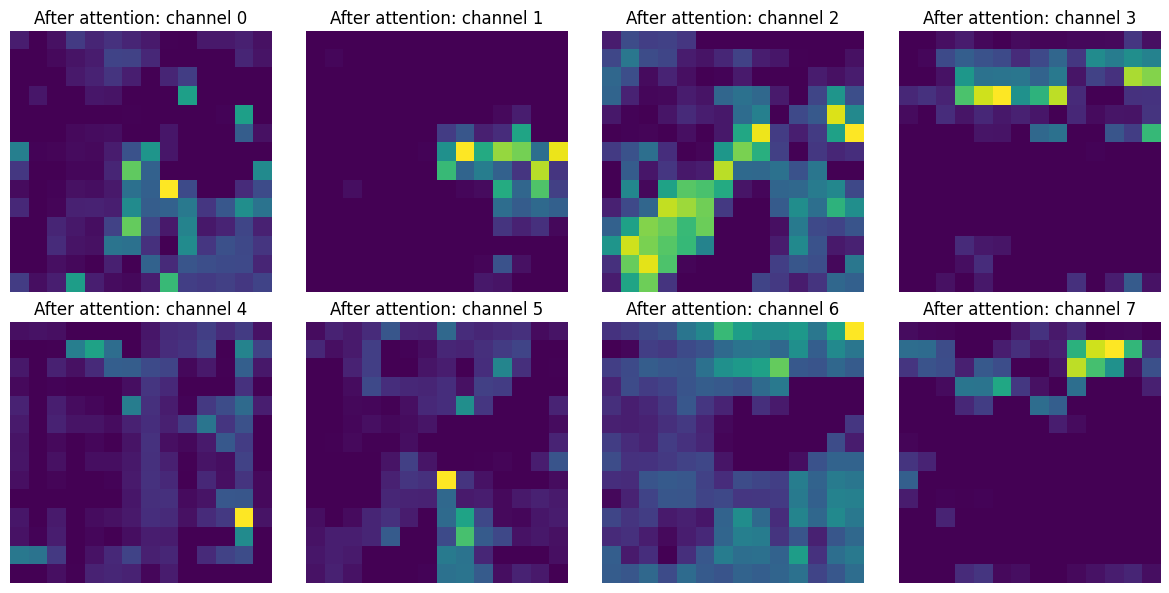

In [ ]:
# Feature map before/after attention, spatial map, channel weights
# P3 feature layer in the shared pretrained ResNet50
probe_base = tf.keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
probe = Model(probe_base.input, probe_base.get_layer("conv4_block6_out").output)
features = probe(x_img, training=False).numpy()[0]

# Before-attention feature maps: display first 8 channels
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(features[:, :, i], cmap="viridis")
    ax.set_title(f"Before attention: channel {i}")
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/08_features_before_attention.png", dpi=160, bbox_inches="tight")
plt.show()

# Generate internal attention weights from the trained channel+spatial P3 model.
m = models["ChannelSpatial_P3"]
channel_layer = m.get_layer("channel_attention")
spatial_layer = m.get_layer("spatial_attention")
# Build a probe that returns the feature tensor immediately before channel attention.
# The functional model layer graph retains this tensor as the input to channel_attention.
pre_attention_tensor = channel_layer.input
pre_probe = Model(m.inputs, pre_attention_tensor)
pre_feat = pre_probe(x_img, training=False)
channel_weights = channel_layer(pre_feat, training=False) / (pre_feat + 1e-8)
channel_weights_np = channel_weights.numpy()[0]
channel_importance = np.mean(channel_weights_np, axis=(0, 1))
top_k = np.argsort(channel_importance)[-10:][::-1]

plt.figure(figsize=(9, 4))
plt.bar([str(int(i)) for i in top_k], channel_importance[top_k])
plt.xlabel("Channel index (top 10)")
plt.ylabel("Mean channel weight")
plt.title("Top 10 channel-attention weights")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/09_channel_attention_weights.png", dpi=160, bbox_inches="tight")
plt.show()

# Spatial attention module receives channel-refined features.
channel_output_tensor = channel_layer.output
spatial_input_probe = Model(m.inputs, channel_output_tensor)
channel_refined = spatial_input_probe(x_img, training=False)
spatial_map = spatial_layer(channel_refined, training=False).numpy()
# Recover the map approximately as output/input; averaging channels gives HxW attention response.
spatial_response = np.mean(spatial_map.numpy() / (channel_refined.numpy() + 1e-8), axis=-1, keepdims=True)
show_overlay(resized_img, spatial_response[0], "Spatial attention overlay (P3)", "10_spatial_attention_overlay.png")

# Feature maps after attention
post_probe = Model(m.inputs, spatial_layer.output)
post_feat = post_probe(x_img, training=False).numpy()[0]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(post_feat[:, :, i], cmap="viridis")
    ax.set_title(f"After attention: channel {i}")
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/11_features_after_attention.png", dpi=160, bbox_inches="tight")
plt.show()

## Task 8 — Grad-CAM for baseline and attention model
Grad-CAM is a post-hoc explanation: it uses gradients of the predicted class score with respect to a convolutional feature map. The code below uses the selected stage's last convolutional feature layer.

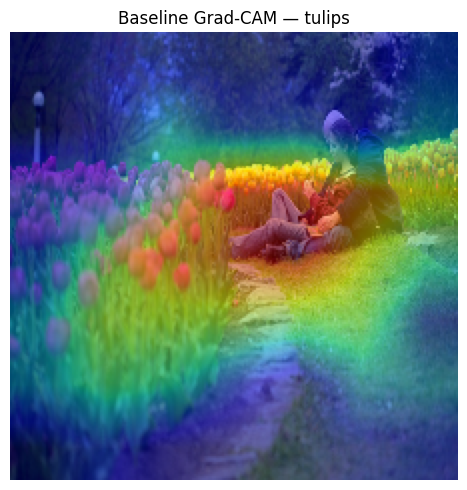

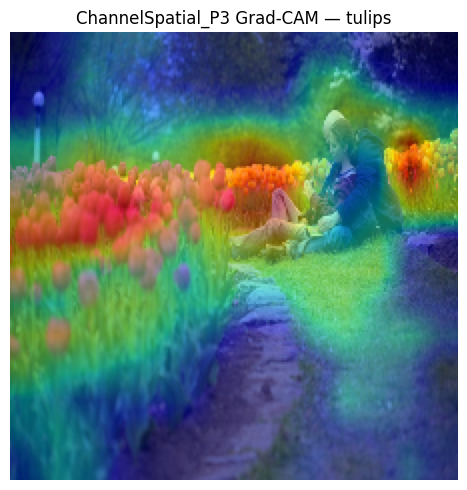

In [ ]:
def make_gradcam_heatmap(model, image_batch, feature_layer_name):
    grad_model = Model(
        model.inputs,
        [model.get_layer(feature_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(image_batch, training=False)
        class_id = tf.argmax(predictions[0])
        class_score = predictions[:, class_id]
    grads = tape.gradient(class_score, conv_outputs)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    heatmap = tf.reduce_sum(weights * conv_outputs, axis=-1)
    heatmap = tf.nn.relu(heatmap)
    heatmap = heatmap / (tf.reduce_max(heatmap, axis=(1, 2), keepdims=True) + 1e-8)
    return heatmap[0].numpy(), int(class_id.numpy())

# Layer name exists in both these models because both use P4/P3 stage outputs respectively.
# Baseline uses conv5; attention P3 uses conv4.
for name, layer_name in [("Baseline", "resnet50_P4"), ("ChannelSpatial_P3", "resnet50_P3")]:
    heatmap, class_id = make_gradcam_heatmap(models[name], x_img, layer_name)
    show_overlay(resized_img, heatmap, f"{name} Grad-CAM — {class_names[class_id]}",
                 f"12_gradcam_{name}.png")

## Task 9 — Compare spatial attention at P2, P3, and P4
This builds small probes with the same spatial-attention module at each stage and plots the attention response for one identical image.

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['image']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


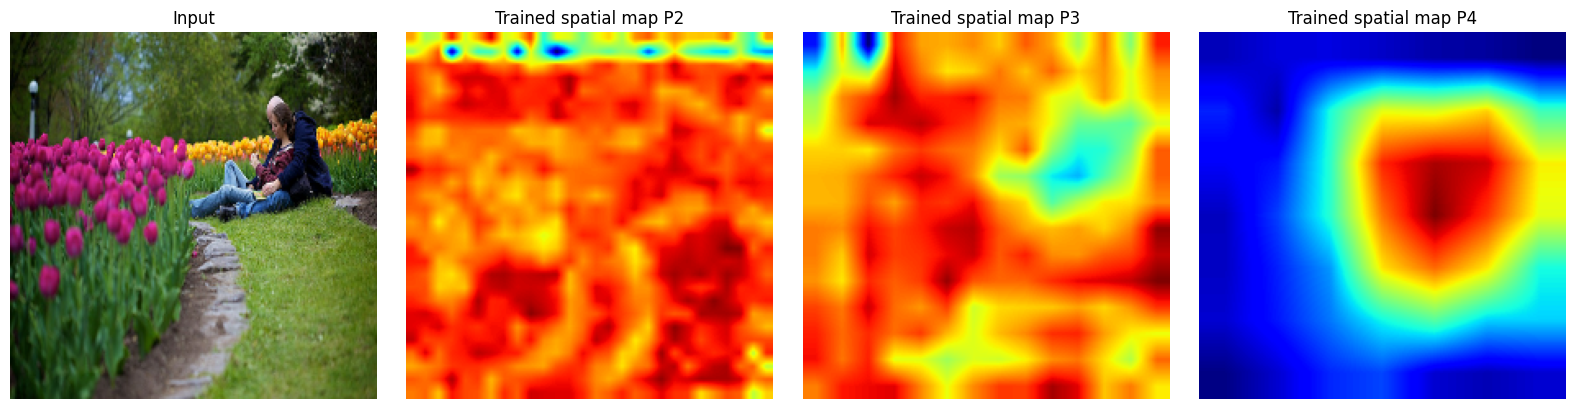

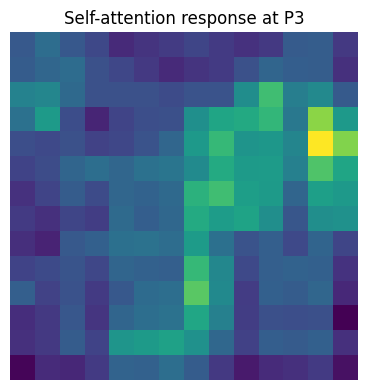

In [ ]:
def trained_spatial_attention_map(model_name, image_batch):
    model = models[model_name]
    spatial_layer = model.get_layer("spatial_attention")
    # The output of spatial attention is feature * attention; divide by the input
    # feature (with a small epsilon) to recover an approximate attention response.
    spatial_input = Model(model.inputs, spatial_layer.input)(image_batch, training=False)
    spatial_output = Model(model.inputs, spatial_layer.output)(image_batch, training=False)
    response = spatial_output / (spatial_input + 1e-8)
    return tf.reduce_mean(response, axis=-1, keepdims=True).numpy()[0]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(resized_img.astype("uint8"))
axes[0].set_title("Input")
axes[0].axis("off")
for ax, pos, model_name in zip(
    axes[1:],
    ["P2", "P3", "P4"],
    ["ChannelSpatial_P2", "ChannelSpatial_P3", "ChannelSpatial_P4"]
):
    amap = trained_spatial_attention_map(model_name, x_img)
    amap = tf.image.resize(amap, (IMG_SIZE, IMG_SIZE)).numpy().squeeze()
    ax.imshow(amap, cmap="jet")
    ax.set_title(f"Trained spatial map {pos}")
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/13_attention_positions_P2_P3_P4.png", dpi=160, bbox_inches="tight")
plt.show()

# Self-attention response for the self-attention experiment
self_model = models["SelfAttention_P3"]
self_layer = self_model.get_layer("self_attention")
self_response_model = Model(self_model.inputs, self_layer.output)
self_response = self_response_model(x_img, training=False).numpy()[0]
response_map = np.mean(np.abs(self_response), axis=-1)
plt.figure(figsize=(5, 4))
plt.imshow(response_map, cmap="viridis")
plt.title("Self-attention response at P3")
plt.axis("off")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/14_self_attention_response.png", dpi=160, bbox_inches="tight")
plt.show()

## Task 10 — Extended ablations: attention order, kernel size, SE, and ECA
These runs are optional extensions in the manual. They use the same training/validation/test split.

In [ ]:
# Attention order: Channel -> Spatial versus Spatial -> Channel at P3
# Uncomment to run (each adds another model training run).
# order_models, order_histories = {}, {}
# for name, order in [("ChannelThenSpatial_P3", "channel_spatial"), ("SpatialThenChannel_P3", "spatial_channel")]:
#     order_models[name], order_histories[name] = train_one(name, "order", "P3", order=order)
#     models[name] = order_models[name]
#     histories[name] = order_histories[name]

# Spatial kernel size 3, 5, 7 at P3
# kernel_models, kernel_histories = {}, {}
# for k in [3, 5, 7]:
#     name = f"SpatialKernel{k}_P3"
#     kernel_models[name], kernel_histories[name] = train_one(name, "spatial", "P3", kernel_size=k)
#     models[name] = kernel_models[name]
#     histories[name] = kernel_histories[name]

# Additional mechanisms: SE and ECA at P3
# additional_models, additional_histories = {}, {}
# for name, attention in [("SE_P3", "extra_se"), ("ECA_P3", "extra_eca")]:
#     additional_models[name], additional_histories[name] = train_one(name, attention, "P3")
#     models[name] = additional_models[name]
#     histories[name] = additional_histories[name]

## Task 11 — Save a single combined results table
Run after all models you want to compare have been evaluated. If you trained optional models, this evaluates them too.

In [ ]:
# Re-evaluate every model currently stored in `models` and save one final table.
all_results = []
all_predictions = {}
for name, model in models.items():
    r = evaluate_model(model, name)
    all_predictions[name] = (r.pop("y_true"), r.pop("y_pred"))
    all_results.append(r)
final_results_df = pd.DataFrame(all_results)
display(final_results_df.round(4))
final_results_df.to_csv(f"{RESULT_DIR}/final_all_results.csv", index=False)
print("Saved final table to", f"{RESULT_DIR}/final_all_results.csv")

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Trainable Parameters,Total Parameters,Inference Time (s/image)
0,Baseline,0.9165,0.9146,0.9175,0.9156,10245,23597957,0.0181
1,Channel_P3,0.9129,0.9138,0.9149,0.9138,137285,8726469,0.0153
2,Spatial_P3,0.9111,0.9121,0.9125,0.9118,5223,8594407,0.0150
3,ChannelSpatial_P3,0.9093,0.9104,0.9103,0.9097,137383,8726567,0.0148
4,ChannelSpatial_P2,0.7877,0.7934,0.7876,0.7872,35975,1496071,0.0093
5,ChannelSpatial_P4,0.9274,0.9273,0.9277,0.9274,536807,24124519,0.0189
6,SelfAttention_P3,0.9056,0.9056,0.9060,0.9050,1184774,9773958,0.0148


Saved final table to results/final_all_results.csv


## Task 12 — Report discussion checklist and viva answers

Use the actual values/plots generated above to fill your report. Do not claim an attention method is better unless the test results support it.

1. **Purpose of residual connections:** They provide shortcut paths that help gradients flow through deep networks and make deep models easier to train.
2. **conv2_x vs conv5_x:** Earlier stages retain finer spatial detail and detect edges/textures; later stages have lower resolution and more semantic features.
3. **Why resolution decreases:** Downsampling reduces computation and combines local information into broader representations.
4. **Why channels increase:** Deeper stages represent a wider variety of increasingly complex patterns.
5. **Low/intermediate/high-level features:** Low-level = edges/colors; intermediate = parts/patterns; high-level = object/class-related information.
6. **Purpose of attention:** Reweight useful features and reduce the influence of less relevant features.
7. **Channel attention:** Learns which feature channels matter more.
8. **Spatial attention:** Learns which positions in the feature map matter more.
9. **Channel vs spatial attention:** Channel attention weights feature channels; spatial attention weights locations.
10. **Sequential attention:** Channel attention can select useful feature types before spatial attention emphasizes relevant locations, or vice versa.
11. **Why channel attention differs by stage:** The channels represent different kinds of information at different depths.
12. **Why spatial attention can help at intermediate stages:** Intermediate maps can retain both spatial detail and useful object-part information.
13. **Why self-attention is expensive at high resolution:** For N=H×W positions, the attention matrix has N×N entries.
14. **Effect of resolution on attention matrix:** Doubling H and W makes N four times larger and the N×N matrix sixteen times larger.
15. **Effect of insertion position:** Compare measured P2/P3/P4 results; do not assume one position is best.
16. **P2 vs P4 maps:** P2 has finer spatial detail; P4 is coarser and more semantic. Verify this from your generated plots.
17. **Does more attention always help?** No. Extra modules add computation and may overfit or provide redundant information.
18. **Channel→Spatial vs Spatial→Channel:** The order changes the features presented to the second attention module; compare their test metrics.
19. **Spatial kernel size:** Larger kernels use a wider spatial neighborhood but add computation; compare k=3, 5, 7.
20. **SE vs ECA:** SE uses a small bottleneck MLP for channel weighting; ECA uses a lightweight 1-D convolution over the channel descriptor.
21. **CBAM:** Combines channel and spatial attention sequentially.
22. **Self-attention vs channel attention:** Self-attention relates spatial positions to one another; channel attention reweights channels.
23. **Do more parameters guarantee accuracy?** No. Parameter count alone does not guarantee better generalization.
24. **Internal attention vs Grad-CAM:** Internal attention weights are produced by the model's attention module; Grad-CAM uses gradients after a prediction.
25. **Why Grad-CAM is post-hoc:** It is calculated after the model is built/trained to explain a selected prediction.
26. **Background suppression:** Inspect overlays and describe what is actually highlighted.
27. **Correct vs incorrect predictions:** Compare several correctly and incorrectly classified test examples.
28. **Which classes benefit most?** Use class-wise precision/recall and confusion matrices.
29. **What confusion matrices show:** Which true classes are mistaken for which predicted classes.
30. **Why macro F1:** It gives equal importance to each class, unlike accuracy which can hide weak performance on some classes.
31. **Accuracy–complexity trade-off:** Whether an accuracy gain is worth extra parameters/computation.
32. **F1–inference-time trade-off:** Whether macro F1 improvement justifies slower inference.
33. **Why fixed data split:** It makes model comparisons fair.
34. **Why fixed training protocol:** Then the attention choice is the main factor changing.
35. **Grad-CAM conclusions:** Describe the regions highlighted in each image; avoid unsupported statements.

### Important report note
The official manual requires quantitative, computational, and qualitative analysis. Include the CSV result table, learning curves, confusion matrices, attention visualizations, and Grad-CAM comparisons in the report. The output files are in the `results/` folder.